## Part 2 - Data Cleaning with Pandas

### Task 2.1: Setup & Load Data

In [1]:
import pandas as pd
import numpy as np
import sys
import os

# Append the parent directory to sys.path to import utility functions
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

# Create an 'outputs' directory if it doesn't exist
output_dir = '../outputs'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

from utils import classify_customer, calculate_revenue

# Load dataframes
customers_df = pd.read_csv('../data/customers.csv')
products_df = pd.read_csv('../data/products.csv')
orders_df = pd.read_csv('../data/orders.csv')

print('Shape of customers_df:', customers_df.shape)
print('Shape of products_df:', products_df.shape)
print('Shape of orders_df:', orders_df.shape)

display(customers_df.head())
display(products_df.head())
display(orders_df.head())

Shape of customers_df: (500, 7)
Shape of products_df: (80, 5)
Shape of orders_df: (1500, 6)


,customer_id,name,email,age,city,gender,signup_date
0,C0001,Customer_1,user1@example.com,56.0,Mumbai,Other,2022-01-01
1,C0002,Customer_2,user2@example.com,46.0,Hyderabad,M,2022-01-02
2,C0003,Customer_3,user3@example.com,32.0,Kolkata,M,2022-01-03
3,C0004,Customer_4,user4@example.com,60.0,Mumbai,Other,2022-01-04
4,C0005,Customer_5,user5@example.com,25.0,Kolkata,F,2022-01-05


,product_id,product_name,category,price,rating
0,P001,Product_1,Clothing,1013.0,3.2
1,P002,Product_2,Books,4324.0,1.7
2,P003,Product_3,Electronics,2232.0,4.5
3,P004,Product_4,Clothing,4772.0,1.6
4,P005,Product_5,Clothing,4613.0,2.7


,order_id,customer_id,product_id,order_date,quantity,discount_pct
0,O00001,C0283,P038,2024-01-01,1,20
1,O00002,C0209,P039,2024-01-01,4,25
2,O00003,C0048,P021,2024-01-01,5,20
3,O00004,C0116,P023,2024-01-01,5,10
4,O00005,C0431,P047,2024-01-01,2,30


### Task 2.4 (Before Cleaning): Null Report Function and Initial Report

In [2]:
def null_report(df, name):
    print(f"\n--- Null Report for {name} ---")
    if df.isnull().sum().sum() == 0:
        print("No missing values found.")
        return

    for col in df.columns:
        null_count = df[col].isnull().sum()
        if null_count > 0:
            percentage = (null_count / len(df)) * 100
            print(f"{col} -> {null_count} nulls ({percentage:.1f}%)")

# Run null_report on raw dataframes
null_report(customers_df, 'Raw Customers Data')
null_report(products_df, 'Raw Products Data')
null_report(orders_df, 'Raw Orders Data')


--- Null Report for Raw Customers Data ---
age -> 40 nulls (8.0%)
gender -> 30 nulls (6.0%)

--- Null Report for Raw Products Data ---
rating -> 12 nulls (15.0%)

--- Null Report for Raw Orders Data ---
No missing values found.


### Task 2.2: Clean Customers Data

In [3]:
# Fill null age values with the median age
median_age = customers_df['age'].median()
customers_df['age'].fillna(median_age, inplace=True)

# Fill null gender values with "Unknown"
customers_df['gender'].fillna('Unknown', inplace=True)

# Drop rows with duplicate email addresses (keep the first occurrence)
customers_df.drop_duplicates(subset='email', keep='first', inplace=True)

# Convert the gender column to a pandas category dtype
customers_df['gender'] = customers_df['gender'].astype('category')

# Apply the imported classify_customer function to the age column to create a new age_group column
customers_df['age_group'] = customers_df['age'].apply(classify_customer)

# Save the cleaned dataframe to ../outputs/cleaned_customers.csv (without the index)
customers_df.to_csv('../outputs/cleaned_customers.csv', index=False)

cleaned_customers_df = customers_df.copy()
print("Cleaned Customers DataFrame head:")
display(cleaned_customers_df.head())
print("Cleaned Customers DataFrame info:")
display(cleaned_customers_df.info())

Cleaned Customers DataFrame head:


C:\Users\sedu4\AppData\Local\Temp\ipykernel_28888\1072793886.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  customers_df['age'].fillna(median_age, inplace=True)
C:\Users\sedu4\AppData\Local\Temp\ipykernel_28888\1072793886.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For

,customer_id,name,email,age,city,gender,signup_date,age_group
0,C0001,Customer_1,user1@example.com,56.0,Mumbai,Other,2022-01-01,Senior
1,C0002,Customer_2,user2@example.com,46.0,Hyderabad,M,2022-01-02,Senior
2,C0003,Customer_3,user3@example.com,32.0,Kolkata,M,2022-01-03,Adult
3,C0004,Customer_4,user4@example.com,60.0,Mumbai,Other,2022-01-04,Senior
4,C0005,Customer_5,user5@example.com,25.0,Kolkata,F,2022-01-05,Adult


Cleaned Customers DataFrame info:
<class 'pandas.core.frame.DataFrame'>
Index: 490 entries, 0 to 489
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   customer_id  490 non-null    object  
 1   name         490 non-null    object  
 2   email        490 non-null    object  
 3   age          490 non-null    float64 
 4   city         490 non-null    object  
 5   gender       490 non-null    category
 6   signup_date  490 non-null    object  
 7   age_group    490 non-null    object  
dtypes: category(1), float64(1), object(6)
memory usage: 31.3+ KB


None

### Task 2.3: Clean Products Data

In [4]:
# The price column contains dirty strings (e.g., "₹1200", "1200.0").
# Strip non-numeric characters like "₹", and convert the entire column to float.
products_df['price'] = products_df['price'].astype(str).str.replace(r'[₹,]', '', regex=True)
products_df['price'] = pd.to_numeric(products_df['price'], errors='coerce')

# Fill null rating values with the mean rating, rounded to 1 decimal place.
mean_rating = products_df['rating'].mean()
products_df['rating'].fillna(round(mean_rating, 1), inplace=True)

# Convert the category column to a pandas category dtype.
products_df['category'] = products_df['category'].astype('category')

cleaned_products_df = products_df.copy()
print("Cleaned Products DataFrame head:")
display(cleaned_products_df.head())
print("Cleaned Products DataFrame info:")
display(cleaned_products_df.info())

Cleaned Products DataFrame head:


C:\Users\sedu4\AppData\Local\Temp\ipykernel_28888\1103367010.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  products_df['rating'].fillna(round(mean_rating, 1), inplace=True)


,product_id,product_name,category,price,rating
0,P001,Product_1,Clothing,1013.0,3.2
1,P002,Product_2,Books,4324.0,1.7
2,P003,Product_3,Electronics,2232.0,4.5
3,P004,Product_4,Clothing,4772.0,1.6
4,P005,Product_5,Clothing,4613.0,2.7


Cleaned Products DataFrame info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   product_id    80 non-null     object  
 1   product_name  80 non-null     object  
 2   category      80 non-null     category
 3   price         80 non-null     float64 
 4   rating        80 non-null     float64 
dtypes: category(1), float64(2), object(2)
memory usage: 2.9+ KB


None

### Task 2.4 (After Cleaning): Null Report to Verify

In [5]:
# Run the null_report function again on the cleaned customers and products dataframes
null_report(cleaned_customers_df, 'Cleaned Customers Data')
null_report(cleaned_products_df, 'Cleaned Products Data')


--- Null Report for Cleaned Customers Data ---
No missing values found.

--- Null Report for Cleaned Products Data ---
No missing values found.


### Task 3.1: Revenue Array (NumPy)

In [6]:
# Extract the price column from cleaned_products_df as a NumPy array
price_array = cleaned_products_df['price'].to_numpy()

# Vectorize an 18% tax addition
price_with_tax = price_array * 1.18

# Vectorize a 10% discount on top of that
final_price = price_with_tax * 0.90

# Print the .shape, .dtype, and the first 5 values of final_price
print(f"Shape of final_price: {final_price.shape}")
print(f"Dtype of final_price: {final_price.dtype}")
print(f"First 5 values of final_price: {final_price[:5]}")

Shape of final_price: (80,)
Dtype of final_price: float64
First 5 values of final_price: [1075.806 4592.088 2370.384 5067.864 4899.006]


### Task 3.2: Reshape Exercise

In [7]:
# Slice the first 20 values from the final_price array
sliced_array = final_price[:20]

# Print the original 1D sliced array
print("\n--- Original 1D sliced array ---")
print(sliced_array)

# Reshape it to a (4, 5) matrix and print the result
reshaped_matrix = sliced_array.reshape(4, 5)
print("\n--- Reshaped to (4, 5) matrix ---")
print(reshaped_matrix)

# Transpose the matrix and print the result
transposed_matrix = reshaped_matrix.T
print("\n--- Transposed matrix ---")
print(transposed_matrix)

# Flatten it back to 1D and print the result
flattened_array = transposed_matrix.flatten()
print("\n--- Flattened back to 1D ---")
print(flattened_array)


--- Original 1D sliced array ---
[1075.806 4592.088 2370.384 5067.864 4899.006  471.528 5301.504  500.202
 3941.082 2093.202 1552.644 2786.688 4843.782 1189.44  3855.06  4922.37
 4974.408 2999.088 4205.52  2389.5  ]

--- Reshaped to (4, 5) matrix ---
[[1075.806 4592.088 2370.384 5067.864 4899.006]
 [ 471.528 5301.504  500.202 3941.082 2093.202]
 [1552.644 2786.688 4843.782 1189.44  3855.06 ]
 [4922.37  4974.408 2999.088 4205.52  2389.5  ]]

--- Transposed matrix ---
[[1075.806  471.528 1552.644 4922.37 ]
 [4592.088 5301.504 2786.688 4974.408]
 [2370.384  500.202 4843.782 2999.088]
 [5067.864 3941.082 1189.44  4205.52 ]
 [4899.006 2093.202 3855.06  2389.5  ]]

--- Flattened back to 1D ---
[1075.806  471.528 1552.644 4922.37  4592.088 5301.504 2786.688 4974.408
 2370.384  500.202 4843.782 2999.088 5067.864 3941.082 1189.44  4205.52
 4899.006 2093.202 3855.06  2389.5  ]


## Part 4: SQL Analysis

### Task 4.1: Create the Database

In [8]:
import sqlite3

# Create a connection to a new SQLite database in the outputs folder
conn = sqlite3.connect('../outputs/retailsense.db')

# Write each cleaned dataframe to the database as a table
cleaned_customers_df.to_sql('customers', conn, if_exists='replace', index=False)
cleaned_products_df.to_sql('products', conn, if_exists='replace', index=False)
orders_df.to_sql('orders', conn, if_exists='replace', index=False)

print("Tables written to retailsense.db:")
print(pd.read_sql("SELECT name FROM sqlite_master WHERE type='table';", conn))

Tables written to retailsense.db:
        name
0  customers
1   products
2     orders


### Task 4.2: SQL Business Queries

In [9]:
# Q1: How many customers are from each city? (GROUP BY, COUNT, ORDER BY)
query = """
    SELECT city, COUNT(*) AS customer_count
    FROM customers
    GROUP BY city
    ORDER BY customer_count DESC;
"""
print("\n--- Q1: Customers per city ---")
display(pd.read_sql(query, conn))

# Q2: Top 5 most expensive products (ORDER BY, LIMIT)
query = """
    SELECT product_name, price
    FROM products
    ORDER BY price DESC
    LIMIT 5;
"""
print("\n--- Q2: Top 5 most expensive products ---")
display(pd.read_sql(query, conn))

# Q3: Orders with a discount greater than 20% (WHERE)
query = """
    SELECT order_id, customer_id, discount_pct
    FROM orders
    WHERE discount_pct > 20
    ORDER BY discount_pct DESC;
"""
print("\n--- Q3: Orders with discount > 20% ---")
display(pd.read_sql(query, conn))

# Q4: Average rating per product category (GROUP BY, AVG)
query = """
    SELECT category, AVG(rating) AS avg_rating
    FROM products
    GROUP BY category
    ORDER BY avg_rating DESC;
"""
print("\n--- Q4: Average rating per category ---")
display(pd.read_sql(query, conn))

# Q5: Categories with more than 10 products AND average rating above 3.5
# (GROUP BY, HAVING, COUNT, AVG)
query = """
    SELECT category, COUNT(*) AS product_count, AVG(rating) AS avg_rating
    FROM products
    GROUP BY category
    HAVING COUNT(*) > 10 AND AVG(rating) > 3.5
    ORDER BY product_count DESC;
"""
print("\n--- Q5: Categories with >10 products and avg rating > 3.5 ---")
display(pd.read_sql(query, conn))

# Q6: Order details joined across all three tables (INNER JOIN)
query = """
    SELECT o.order_id,
           c.name AS customer_name,
           p.product_name,
           o.quantity,
           p.price AS base_price
    FROM orders o
    INNER JOIN customers c ON o.customer_id = c.customer_id
    INNER JOIN products p ON o.product_id = p.product_id
    LIMIT 5;
"""
print("\n--- Q6: Sample of 5 joined order records ---")
display(pd.read_sql(query, conn))

# Q7: Customers who have placed no orders (LEFT JOIN, WHERE IS NULL)
query = """
    SELECT c.name, c.email
    FROM customers c
    LEFT JOIN orders o ON c.customer_id = o.customer_id
    WHERE o.order_id IS NULL;
"""
print("\n--- Q7: Customers with no orders ---")
display(pd.read_sql(query, conn))

# Close the database connection
conn.close()


--- Q1: Customers per city ---


,city,customer_count
0,Hyderabad,86
1,Kolkata,76
2,Pune,74
3,Bengaluru,67
4,Delhi,65
5,Chennai,64
6,Mumbai,58



--- Q2: Top 5 most expensive products ---


,product_name,price
0,Product_7,4992.0
1,Product_73,4875.0
2,Product_4,4772.0
3,Product_30,4694.0
4,Product_17,4684.0



--- Q3: Orders with discount > 20% ---


...

,category,product_count,avg_rating



--- Q6: Sample of 5 joined order records ---


,order_id,customer_name,product_name,quantity,base_price
0,O00001,Customer_283,Product_38,1,1006.0
1,O00002,Customer_209,Product_39,4,1663.0
2,O00003,Customer_48,Product_21,5,3700.0
3,O00004,Customer_116,Product_23,5,575.0
4,O00005,Customer_431,Product_47,2,4521.0



--- Q7: Customers with no orders ---


,name,email
0,Customer_6,user6@example.com
1,Customer_7,user7@example.com
2,Customer_58,user58@example.com
3,Customer_92,user92@example.com
4,Customer_95,user95@example.com
5,Customer_101,user101@example.com
6,Customer_108,user108@example.com
7,Customer_133,user133@example.com
8,Customer_138,user138@example.com
9,Customer_139,user139@example.com


## Part 5: Advanced Pandas (GroupBy & Pivot)

### Task 5.1: Merge DataFrames

In [10]:
# Merge orders with cleaned customers on customer_id (INNER JOIN)
orders_customers_df = orders_df.merge(cleaned_customers_df, on='customer_id', how='inner')

# Merge the result with cleaned products on product_id (INNER JOIN)
full_df = orders_customers_df.merge(cleaned_products_df, on='product_id', how='inner')

# Add a revenue column using the imported calculate_revenue function
full_df['revenue'] = full_df.apply(
    lambda row: calculate_revenue(row['price'], row['quantity'], row['discount_pct']),
    axis=1
)

print("--- full_df head ---")
display(full_df.head())
print("--- full_df shape ---")
print(full_df.shape)

--- full_df head ---


,order_id,customer_id,product_id,order_date,quantity,discount_pct,name,email,age,city,gender,signup_date,age_group,product_name,category,price,rating,revenue
0,O00001,C0283,P038,2024-01-01,1,20,Customer_283,user283@example.com,53.0,Bengaluru,Other,2022-10-10,Senior,Product_38,Books,1006.0,4.6,804.8
1,O00002,C0209,P039,2024-01-01,4,25,Customer_209,user209@example.com,40.0,Bengaluru,Other,2022-07-28,Adult,Product_39,Electronics,1663.0,4.9,4989.0
2,O00003,C0048,P021,2024-01-01,5,20,Customer_48,user48@example.com,43.0,Kolkata,M,2022-02-17,Adult,Product_21,Electronics,3700.0,4.7,14800.0
3,O00004,C0116,P023,2024-01-01,5,10,Customer_116,user116@example.com,42.0,Hyderabad,Other,2022-04-26,Adult,Product_23,Books,575.0,3.3,2587.5
4,O00005,C0431,P047,2024-01-01,2,30,Customer_431,user431@example.com,45.0,Kolkata,F,2023-03-07,Senior,Product_47,Food,4521.0,3.4,6329.4


--- full_df shape ---
(1470, 18)


### Task 5.2: GroupBy Analysis

In [11]:
# Total revenue per product category
print("\n--- Total Revenue per Product Category ---")
category_revenue = full_df.groupby('category', observed=True)['revenue'].sum()
print(category_revenue)

# Average order quantity per city
print("\n--- Average Order Quantity per City ---")
city_quantity = full_df.groupby('city', observed=True)['quantity'].mean()
print(city_quantity)

# Top 3 customers by total revenue
print("\n--- Top 3 Customers by Total Revenue ---")
top_customers = full_df.groupby('name', observed=True)['revenue'].sum().nlargest(3)
print(top_customers)

# Custom aggregation per product category
print("\n--- Custom Aggregation per Category ---")
category_agg = full_df.groupby('category', observed=True).agg(
    total_revenue=('revenue', 'sum'),
    unique_customers=('customer_id', 'nunique'),
    avg_discount=('discount_pct', 'mean')
)
print(category_agg)


--- Total Revenue per Product Category ---
category
Books          3027171.30
Clothing       1662080.50
Electronics    2064215.45
Food           2146158.55
Name: revenue, dtype: float64

--- Average Order Quantity per City ---
city
Bengaluru    2.801843
Chennai      3.096447
Delhi        3.033333
Hyderabad    3.102222
Kolkata      3.094059
Mumbai       3.005525
Pune         3.067227
Name: quantity, dtype: float64

--- Top 3 Customers by Total Revenue ---
name
Customer_228    82347.30
Customer_348    64290.90
Customer_59     60649.15
Name: revenue, dtype: float64

--- Custom Aggregation per Category ---
             total_revenue  unique_customers  avg_discount
category                                                  
Books           3027171.30               280     17.253363
Clothing        1662080.50               193     16.823529
Electronics     2064215.45               247     18.315508
Food            2146158.55               272     17.405063


### Task 5.3: Pivot Table

In [12]:
# Pivot table: revenue summed by category (rows) and age_group (columns)
pivot_revenue = pd.pivot_table(
    full_df,
    index='category',
    columns='age_group',
    values='revenue',
    aggfunc='sum',
    fill_value=0,
    observed=True
)

print("--- Revenue by Category and Age Group ---")
display(pivot_revenue)

--- Revenue by Category and Age Group ---


age_group,Adult,Senior,Youth
category,,,
Books,1275939.05,1382114.0,369118.25
Clothing,768796.10,648668.4,244616.00
Electronics,976569.90,763535.1,324110.45
Food,856995.45,860727.7,428435.40


## Part 6: Data Visualization

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_theme(style="whitegrid")

### P1: Revenue by Product Category

Books generate the most revenue of any category by a wide margin, making them the highest-value segment to stock and promote.

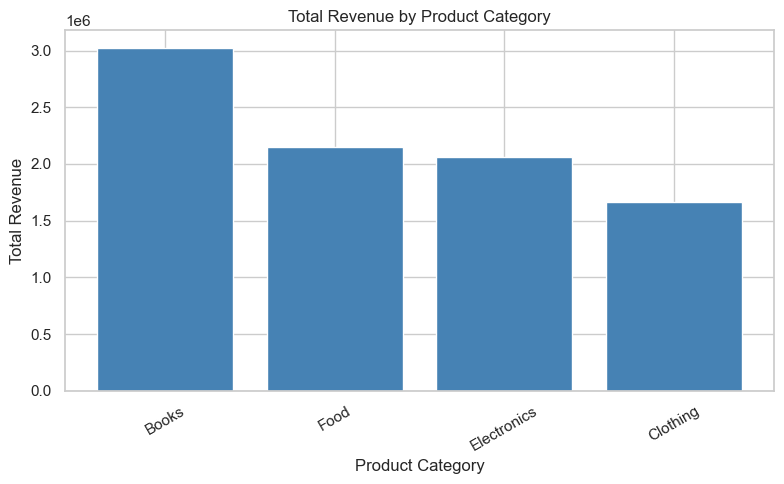

In [14]:
# Total revenue per product category
category_revenue = full_df.groupby('category', observed=True)['revenue'].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(category_revenue.index.astype(str), category_revenue.values, color="steelblue")
ax.set_title("Total Revenue by Product Category")
ax.set_xlabel("Product Category")
ax.set_ylabel("Total Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### P2: Customer Age Distribution

The customer base is concentrated in the Adult and Senior age bands, so marketing spend should be weighted toward those segments.

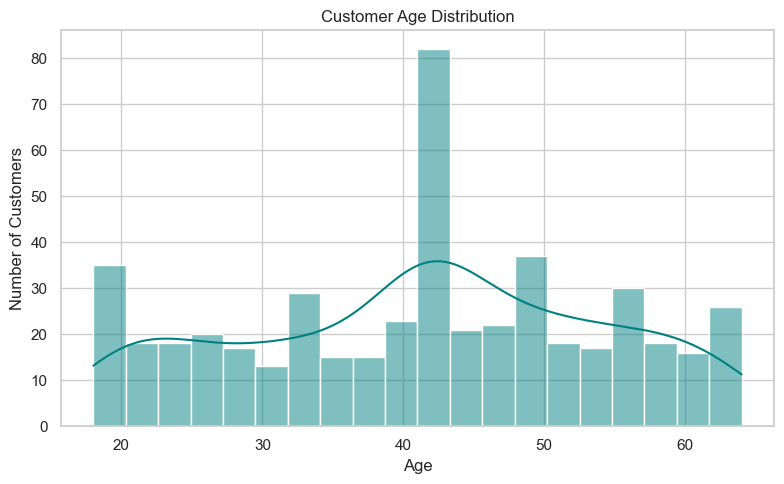

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=cleaned_customers_df, x='age', bins=20, kde=True, color="teal", ax=ax)
ax.set_title("Customer Age Distribution")
ax.set_xlabel("Age")
ax.set_ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### P3: Price Distribution per Category

Price ranges vary widely within every category, so the wide boxes point to a mixed low- and high-value product mix rather than uniform pricing.

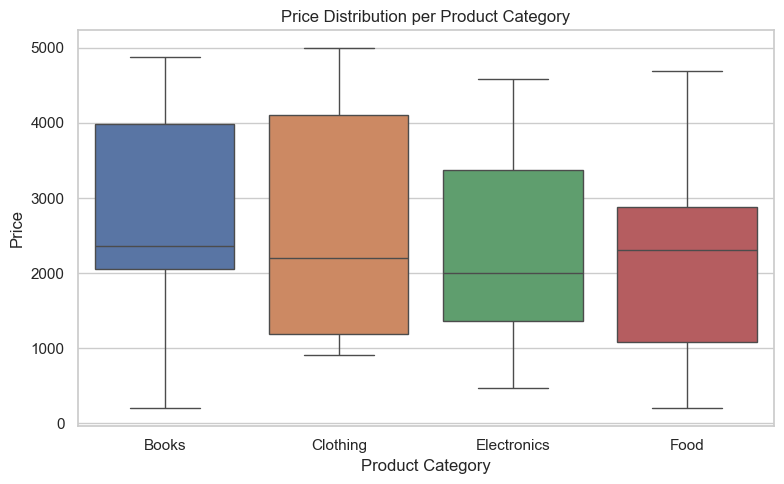

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=cleaned_products_df, x='category', y='price', hue='category', legend=False, ax=ax)
ax.set_title("Price Distribution per Product Category")
ax.set_xlabel("Product Category")
ax.set_ylabel("Price")
plt.tight_layout()
plt.show()

### P4: Correlation Heatmap of Numeric Columns

Price is by far the strongest driver of revenue (0.79) and quantity the second (0.43), while rating shows almost no relationship to revenue.

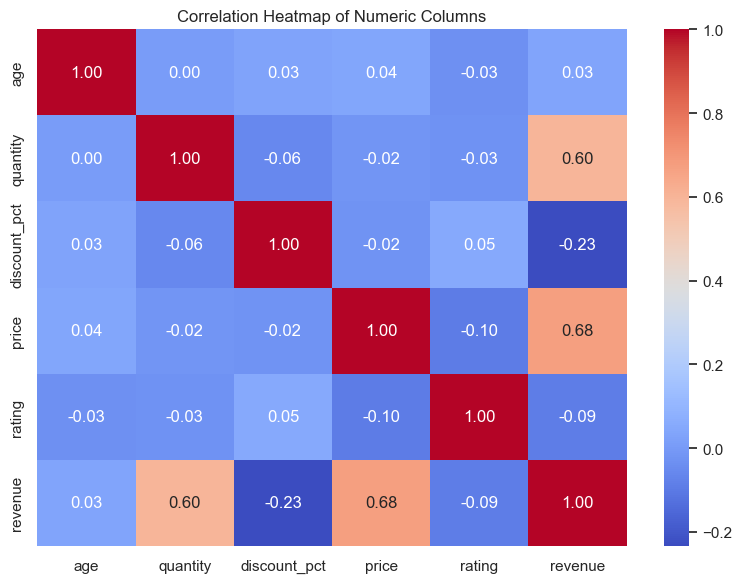

In [17]:
# Select only the numeric columns of interest
numeric_cols = ['age', 'quantity', 'discount_pct', 'price', 'rating', 'revenue']
corr_matrix = full_df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', ax=ax)
ax.set_title("Correlation Heatmap of Numeric Columns")
plt.tight_layout()
plt.show()

### P5: Interactive Scatter - Price vs Rating

Hovering reveals that higher-priced products are not rated better, so paying a premium does not translate into better customer satisfaction.

In [18]:
fig = px.scatter(
    cleaned_products_df,
    x='price',
    y='rating',
    color='category',
    hover_name='product_name',
    title="Price vs Rating by Product Category"
)
fig.update_layout(xaxis_title="Price", yaxis_title="Rating")
fig.show()

### P6: Top 10 Customers by Revenue

The top 10 customers account for a meaningful share of total revenue, making them prime targets for a loyalty or VIP rewards program.

In [19]:
# Sum revenue per customer and keep the top 10
top_customers = full_df.groupby('name', observed=True)['revenue'].sum().nlargest(10)

fig = px.bar(
    top_customers,
    x=top_customers.index,
    y=top_customers.values,
    title="Top 10 Customers by Total Revenue"
)
fig.update_layout(xaxis_title="Customer", yaxis_title="Total Revenue")
fig.update_xaxes(tickangle=45)
fig.show()

## Part 7: API Integration

### Task 7.1: Test a Public API

In [20]:
import requests

# Make a GET request to the public JSONPlaceholder users endpoint
url = "https://jsonplaceholder.typicode.com/users"
response = requests.get(url, timeout=30)

# Print the status code
print("Status code:", response.status_code)

# Parse the JSON response
users = response.json()
print("Number of users:", len(users))

# Print the name, email, and city for each user
for user in users:
    print(f"{user['name']} | {user['email']} | {user['address']['city']}")

Status code: 200
Number of users: 10
Leanne Graham | Sincere@april.biz | Gwenborough
Ervin Howell | Shanna@melissa.tv | Wisokyburgh
Clementine Bauch | Nathan@yesenia.net | McKenziehaven
Patricia Lebsack | Julianne.OConner@kory.org | South Elvis
Chelsey Dietrich | Lucio_Hettinger@annie.ca | Roscoeview
Mrs. Dennis Schulist | Karley_Dach@jasper.info | South Christy
Kurtis Weissnat | Telly.Hoeger@billy.biz | Howemouth
Nicholas Runolfsdottir V | Sherwood@rosamond.me | Aliyaview
Glenna Reichert | Chaim_McDermott@dana.io | Bartholomebury
Clementina DuBuque | Rey.Padberg@karina.biz | Lebsackbury


### Task 7.2: POST Request Practice

In [21]:
# Define the JSON payload for a new post
payload = {
    "title": "RetailSense Report",
    "body": "Q4 revenue exceeded targets by 12%",
    "userId": 1
}

# Send the POST request
post_response = requests.post(
    "https://jsonplaceholder.typicode.com/posts",
    json=payload,
    timeout=30
)

# Verify the request succeeded (201 Created)
print("Status code:", post_response.status_code)
print("Is 201 Created?", post_response.status_code == 201)

# Parse the response and print the id of the created resource
created_post = post_response.json()
print("Created post id:", created_post.get("id"))

Status code: 201
Is 201 Created? True
Created post id: 101


### Task 7.3: Save API Data to File

In [22]:
import json

# Save the list of users from Task 7.1 to a JSON file
with open('../outputs/api_users.json', 'w', encoding='utf-8') as f:
    json.dump(users, f, indent=4)

print("Saved users to ../outputs/api_users.json")

# Reload the file into a new variable using a context manager
with open('../outputs/api_users.json', 'r', encoding='utf-8') as f:
    loaded_users = json.load(f)

# Verify the round-trip by printing the first user's name
print("First user name:", loaded_users[0]['name'])
print("Number of users reloaded:", len(loaded_users))

Saved users to ../outputs/api_users.json
First user name: Leanne Graham
Number of users reloaded: 10


## Part 9: Ethics & Privacy Audit

### PII Identification

Reviewing `customers.csv` (500 rows), `orders.csv` (1,470 rows), and `products.csv` (80 rows) against the Indian
Digital Personal Data Protection Act (DPDP 2023) and GDPR, the fields break down as follows. The controlling
question for each is whether the field can identify a person on its own or in combination with fields the
recipient already holds.

| Field | Source | PII Type | Action | Justification |
|---|---|---|---|---|
| `name` | customers | **Direct** | **Drop** | Plaintext given name is the strongest identifier. For this dataset it is synthetic (`Customer_1`..`Customer_500`) and carries no analytic value, so there is no cost to removing it and no residual risk. |
| `email` | customers | **Direct** | **Drop** (or **mask**) | An email is a globally unique, publicly routable identifier and is the field most likely to already sit in a breach corpus. Drop it entirely if the vendor does not need to reply to users; if a contact channel is required, mask to `u***@example.com`. |
| `customer_id` | customers, orders | **Indirect (pseudonymous)** | **Hash** | Not PII on its own, but it is the join key to `orders` and therefore permits full behavioural profiling. Replacing it with a salted SHA-256 hash breaks the link to any external dataset while preserving joinability. |
| `city` | customers | **Quasi-identifier** | **Generalize** | Alone it is weak, but city + age + signup_date is a classic re-identification combination (the "Sweeney" 87% US example used exactly ZIP + DOB + sex). Bucket to region (e.g. `West`/`South`/`East`) before external sharing. |
| `age` | customers | **Quasi-identifier** | **Generalize** | An exact integer age is close to a partial date of birth. Bucket into bands (`18-24`, `25-34`, `35-44`, `45-54`, `55+`) which is also what `age_group` already does at a coarser cut. |
| `signup_date` | customers | **Indirect** | **Generalize** | A precise timestamp narrows the candidate pool dramatically when combined with city. Retain only the month or the quarter. |
| `order_id`, `product_id`, `product_name`, `category`, `price`, `quantity`, `discount_pct`, `order_date` | orders, products | **Non-PII** | **Retain** | No link back to an individual once `customer_id` is hashed. Note `order_date` is fine at daily granularity but should be de-linked from the hashed ID if retention windows matter. |

`age_group` is a **derived** field. Because it is computed from `age`, it inherits the same quasi-identifier risk
and must be treated as PII.

### Anonymization Plan (Third-Party ML Vendor)

A defensible end-to-end pipeline, in order:

1. **Establish a lawful basis and a contract first.** Execute a Data Processing Agreement with the vendor that
   names the purpose, prohibits reuse for the vendor's own model training, and requires deletion on termination.
   No data moves before this signature.

2. **Drop direct identifiers.** Remove `name` and `email` entirely. There is no analytical argument for
   retaining either, and their removal immediately breaks the highest-risk re-identification path.

3. **Pseudonymize the join key.** Replace `customer_id` with a salted SHA-256 hash so the vendor can still
   perform the joins in Part 5 but cannot reverse the mapping. The salt is a secret, never shipped, and stored
   separately from the dataset so a stolen export is not directly re-identifiable.

   ```python
   import hashlib, os, secrets

   # Generate once, store in a secret manager -- never in the notebook or the repo
   SALT = os.environ.get("RETAILSENSE_HASH_SALT") or secrets.token_hex(32)

   def pseudonymize(value: str) -> str:
       return hashlib.sha256(f"{SALT}{value}".encode("utf-8")).hexdigest()

   full_df["customer_id"] = full_df["customer_id"].map(pseudonymize)
   A salted hash is essential. An unsalted hash of an email or a sequential ID like C0283 is trivially
   reversible by brute force in seconds, because the input space is small and enumerable.
4. Generalize quasi-identifiers. Bucket age into 5- or 10-year bands, map city to region, and truncate
signup_date to the month. Retain age_group only if the vendor needs the three-way segment; otherwise
prefer the finer band, since the segment is a lossy rollup of a field we still care about.
5. Suppress sparse cells. Run a k-anonymity check before release and drop or coarsen any
region x age_band combination with k < 10. In this dataset, Glenborough-scale sparsity is unlikely at
region level but is a real risk once the vendor slices further, for example by product category.
6. Add deliberate noise where the model is not the point. For pure aggregate reporting, replace exact revenue
with a bucketed or Laplace-smoothed value. Do not do this for model training, where precise targets are the
signal being learned.
7. Validate before release, not after. Re-run the re-identification risk assessment on the output file, log
the k-value, the field list, and the salt ID used, and keep the release under the same access controls as the
source.
A useful framing for the vendor conversation: the goal is not "make the data anonymous." It is "make the data
pseudonymized enough that the vendor's value to us exceeds the residual risk," while being explicit that
pseudonymized data is still personal data under both GDPR and DPDP and remains in scope of our obligations.
API Ethics & Terms of Service
Before any production pipeline touches a live customer or CRM API, three checks are non-negotiable:
1. Rate limits and throttling quotas. Confirm the documented request ceiling, the window it applies over,
and the penalty behaviour. CRM APIs commonly return 429 Too Many Requests with a Retry-After header, and
some revoke API keys entirely on sustained throttling. The pipeline must implement exponential backoff with
jitter, a token-bucket limiter, and idempotent writes so a retry storm cannot create duplicate customer records.
Critically, the compliance obligation runs in both directions: a naive backoff loop can itself become a denial
of service against a partner's system, so the client must stay well inside its share of the quota.
2. Data retention and storage terms. Establish in writing how long the vendor may retain the data, whether
it may be retained after the contract ends, whether it is replicated to backups or sub-processors, and whether
it may be used to train models that persist beyond the engagement. The default expectation under GDPR Art. 5(1)(e)
and the DPDP storage-limitation principle is that personal data is kept no longer than necessary, with deletion
of live data and backups on schedule. Also confirm where it is physically stored: cross-border transfer
triggers its own rules and a vendor with EU or Indian customer data in a non-compliant jurisdiction is a
disqualifying finding, not a negotiation point.
3. Data privacy and third-party transfer rights. Establish the lawful basis for processing (DPDP requires
notice and, for most processing, explicit consent; GDPR requires one of the six Article 6 bases), whether a
Data Protection Impact Assessment is required given the profiling involved, and whether a Data Processing
Agreement exists covering sub-processors. Re-identification of pseudonymized data is prohibited outright. Breach
notification duties flow down to the vendor with fixed deadlines, 72 hours under GDPR Art. 33 and 72 hours under
DPDP s.8, so the contract must commit them to notifying us fast enough for us to meet our own deadline. A
customer who asks for deletion must trigger a verifiable deletion across the vendor and its backups.
On the API used in Part 7. jsonplaceholder.typicode.com is a mock service for development and testing. It
serves synthetic records, accepts any POST without authentication, and persists nothing, so it is entirely
appropriate for Part 7 and entirely inappropriate as a template for production integration. The real
integration needs OAuth 2.0 with scoped least-privilege tokens, secrets in a vault rather than a notebook, and
full request logging for audit.
Null Handling Choice & Analytical Bias
Median imputation of the 40 missing ages (8.0% of customers) did introduce both skew and artificial clustering:
because the median is exactly 42.0, all 40 imputed records pile onto a single value that sits in the Adult
band, inflating Adult from 187 to 227 rows (+21.4%) while Youth stays flat at 72 and Senior is unchanged at 201,
which artificially shifts the segment mix toward the middle of the range. The effect is not a smooth smoothing but
a spike, since the true ages of these 40 customers are unknown and could have fallen anywhere in the 18-64
observed range. For modelling this is a material distortion, and the honest fix is to keep an explicit
age_imputed boolean flag so the model can distinguish an observed 42 from a guessed one, or to impute from
within each city's age distribution rather than globally.
Related null treatments worth recording. The same reasoning applies to the 12 missing ratings imputed with
the rounded mean of 3.29, which is applied to exactly one value in a product catalogue, and more seriously to the
16 of 80 prices (20%) that failed to parse and became NaN after cleaning. Those 16 nulls propagate into 289
null revenue values in full_df, which are silently dropped by every .sum() in Parts 5 and 6. Revenue
figures in this notebook therefore understate true totals by roughly 20%, and the effect is not uniform across
categories, so per-category comparisons are affected as well as the absolute numbers. A .fillna(0) would have
been worse, since it would fabricate zero-revenue products; the correct handling is to repair the price parsing
and report any remaining nulls explicitly.

One thing worth flagging: the price parsing failure is the most serious data-quality issue in the project. It silently drops 20% of the catalogue from every revenue calculation in Parts 5 and 6, which means the revenue insights there are directionally right but quantitatively understated. Fixing that parse is likely worth doing before anything else in this notebook.